### pandas 5: Diagramme und Anwendungen - Übungen

In diesem Notebook stellst du Daten mit **Diagrammen** dar, direkt aus pandas heraus (`df.plot`), und wertest in kleinen **Projekten** Datensätze von der Frage
bis zum Diagramm aus.

Die Reihe hat fünf Notebooks:

1. Grundlagen: Series und DataFrame, Spalten, Sortieren, CSV-Dateien
2. Auswählen und aufräumen: Filtern, Text-Spalten, fehlende Werte
3. Gruppieren und auswerten: Aggregatfunktionen, groupby, Pivot-Tabellen, Vergleich mit SQL
4. Verbinden und Zeitreihen: merge, concat, Datum und Zeit
5. **Diagramme und Anwendungen** (dieses Notebook)

Du solltest das Notebook zu den matplotlib-Grundlagen kennen. Die erwarteten Diagramme stehen als Bild unter den Aufgaben.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### Beispieldateien anlegen

**Führe diese Zelle zuerst aus.** Sie legt die Dateien aus den vorigen Notebooks an: `schueler.csv`, `laender.csv` (Einwohner in Tausend, Fläche in km², gerundet, Stand etwa 2023),
`kiosk.csv` (Verkäufe eines Schulkiosks) und `wetter.csv` (Temperatur und Regen von Januar bis Juni 2026, ausgedacht).

In [ ]:
dateien = {
    'schueler.csv': '''name;klasse;alter;wohnort;mathe;deutsch;englisch;fehltage
Ali;9a;15;Tübingen;2;3;2;4
Bea;9a;14;Rottenburg;1;2;1;0
Cem;9b;15;Tübingen;3;3;4;7
Dana;9b;16;Mössingen;2;1;2;2
Emil;9a;15;Tübingen;4;3;3;12
Fiona;9c;14;Rottenburg;1;1;2;1
Gus;9c;15;Mössingen;3;4;3;5
Hanna;9b;14;Tübingen;2;2;1;0
Ida;9c;15;Tübingen;2;3;3;3
Jan;9a;16;Rottenburg;5;4;4;15
Kim;9b;15;Mössingen;1;2;2;1
Lea;9c;14;Tübingen;3;2;2;6
''',
    'laender.csv': '''land,kuerzel,hauptstadt,einwohner,flaeche
Baden-Württemberg,BW,Stuttgart,11280,35748
Bayern,BY,München,13370,70542
Berlin,BE,Berlin,3760,891
Brandenburg,BB,Potsdam,2570,29654
Bremen,HB,Bremen,680,419
Hamburg,HH,Hamburg,1890,755
Hessen,HE,Wiesbaden,6390,21116
Mecklenburg-Vorpommern,MV,Schwerin,1630,23295
Niedersachsen,NI,Hannover,8140,47710
Nordrhein-Westfalen,NW,Düsseldorf,18140,34112
Rheinland-Pfalz,RP,Mainz,4160,19858
Saarland,SL,Saarbrücken,990,2571
Sachsen,SN,Dresden,4090,18450
Sachsen-Anhalt,ST,Magdeburg,2180,20459
Schleswig-Holstein,SH,Kiel,2950,15804
Thüringen,TH,Erfurt,2130,16202
''',
    'kiosk.csv': '''datum;tag;artikel;kategorie;menge;preis
2026-10-05;Montag;Brezel;Backwaren;25;0.80
2026-10-05;Montag;Laugenstange;Backwaren;14;1.00
2026-10-05;Montag;Apfel;Obst;30;0.50
2026-10-05;Montag;Banane;Obst;8;0.40
2026-10-05;Montag;Wasser;Getränke;9;1.00
2026-10-05;Montag;Apfelschorle;Getränke;39;1.50
2026-10-05;Montag;Müsliriegel;Snacks;11;1.20
2026-10-06;Dienstag;Brezel;Backwaren;28;0.80
2026-10-06;Dienstag;Laugenstange;Backwaren;8;1.00
2026-10-06;Dienstag;Apfel;Obst;37;0.50
2026-10-06;Dienstag;Banane;Obst;18;0.40
2026-10-06;Dienstag;Wasser;Getränke;7;1.00
2026-10-06;Dienstag;Apfelschorle;Getränke;10;1.50
2026-10-06;Dienstag;Müsliriegel;Snacks;32;1.20
2026-10-07;Mittwoch;Brezel;Backwaren;31;0.80
2026-10-07;Mittwoch;Laugenstange;Backwaren;9;1.00
2026-10-07;Mittwoch;Apfel;Obst;20;0.50
2026-10-07;Mittwoch;Banane;Obst;10;0.40
2026-10-07;Mittwoch;Wasser;Getränke;40;1.00
2026-10-07;Mittwoch;Apfelschorle;Getränke;32;1.50
2026-10-07;Mittwoch;Müsliriegel;Snacks;8;1.20
2026-10-08;Donnerstag;Brezel;Backwaren;12;0.80
2026-10-08;Donnerstag;Laugenstange;Backwaren;19;1.00
2026-10-08;Donnerstag;Apfel;Obst;8;0.50
2026-10-08;Donnerstag;Banane;Obst;30;0.40
2026-10-08;Donnerstag;Wasser;Getränke;8;1.00
2026-10-08;Donnerstag;Apfelschorle;Getränke;19;1.50
2026-10-08;Donnerstag;Müsliriegel;Snacks;7;1.20
2026-10-09;Freitag;Brezel;Backwaren;50;0.80
2026-10-09;Freitag;Laugenstange;Backwaren;23;1.00
2026-10-09;Freitag;Apfel;Obst;23;0.50
2026-10-09;Freitag;Banane;Obst;31;0.40
2026-10-09;Freitag;Wasser;Getränke;14;1.00
2026-10-09;Freitag;Apfelschorle;Getränke;39;1.50
2026-10-09;Freitag;Müsliriegel;Snacks;12;1.20
2026-10-12;Montag;Brezel;Backwaren;24;0.80
2026-10-12;Montag;Laugenstange;Backwaren;40;1.00
2026-10-12;Montag;Apfel;Obst;16;0.50
2026-10-12;Montag;Banane;Obst;11;0.40
2026-10-12;Montag;Wasser;Getränke;17;1.00
2026-10-12;Montag;Apfelschorle;Getränke;28;1.50
2026-10-12;Montag;Müsliriegel;Snacks;11;1.20
2026-10-13;Dienstag;Brezel;Backwaren;40;0.80
2026-10-13;Dienstag;Laugenstange;Backwaren;9;1.00
2026-10-13;Dienstag;Apfel;Obst;8;0.50
2026-10-13;Dienstag;Banane;Obst;18;0.40
2026-10-13;Dienstag;Wasser;Getränke;36;1.00
2026-10-13;Dienstag;Apfelschorle;Getränke;39;1.50
2026-10-13;Dienstag;Müsliriegel;Snacks;32;1.20
2026-10-14;Mittwoch;Brezel;Backwaren;25;0.80
2026-10-14;Mittwoch;Laugenstange;Backwaren;34;1.00
2026-10-14;Mittwoch;Apfel;Obst;34;0.50
2026-10-14;Mittwoch;Banane;Obst;28;0.40
2026-10-14;Mittwoch;Wasser;Getränke;24;1.00
2026-10-14;Mittwoch;Apfelschorle;Getränke;20;1.50
2026-10-14;Mittwoch;Müsliriegel;Snacks;16;1.20
2026-10-15;Donnerstag;Brezel;Backwaren;20;0.80
2026-10-15;Donnerstag;Laugenstange;Backwaren;10;1.00
2026-10-15;Donnerstag;Apfel;Obst;24;0.50
2026-10-15;Donnerstag;Banane;Obst;38;0.40
2026-10-15;Donnerstag;Wasser;Getränke;36;1.00
2026-10-15;Donnerstag;Apfelschorle;Getränke;26;1.50
2026-10-15;Donnerstag;Müsliriegel;Snacks;33;1.20
2026-10-16;Freitag;Brezel;Backwaren;33;0.80
2026-10-16;Freitag;Laugenstange;Backwaren;19;1.00
2026-10-16;Freitag;Apfel;Obst;12;0.50
2026-10-16;Freitag;Banane;Obst;37;0.40
2026-10-16;Freitag;Wasser;Getränke;31;1.00
2026-10-16;Freitag;Apfelschorle;Getränke;15;1.50
2026-10-16;Freitag;Müsliriegel;Snacks;26;1.20
''',
    'wetter.csv': '''datum,temperatur,regen
2026-01-01,-0.6,3.4
2026-01-02,-3.1,2.5
2026-01-03,-1.4,0.0
2026-01-04,4.0,0.0
2026-01-05,-0.8,1.6
2026-01-06,2.1,0.0
2026-01-07,0.8,0.0
2026-01-08,-1.5,0.0
2026-01-09,-3.9,0.0
2026-01-10,-4.5,0.0
2026-01-11,-0.8,0.0
2026-01-12,-0.2,0.0
2026-01-13,-0.5,0.0
2026-01-14,1.7,0.0
2026-01-15,-1.2,0.0
2026-01-16,-1.3,0.0
2026-01-17,-3.6,2.9
2026-01-18,-5.4,1.8
2026-01-19,1.0,0.0
2026-01-20,1.4,0.8
2026-01-21,2.9,0.0
2026-01-22,-1.1,0.0
2026-01-23,-2.0,0.0
2026-01-24,-1.4,2.7
2026-01-25,-4.0,0.0
2026-01-26,-1.6,0.0
2026-01-27,5.6,0.0
2026-01-28,0.3,0.0
2026-01-29,5.2,0.0
2026-01-30,3.8,0.0
2026-01-31,0.9,0.0
2026-02-01,3.0,0.0
2026-02-02,1.3,0.2
2026-02-03,6.2,0.0
2026-02-04,5.5,2.3
2026-02-05,0.6,0.1
2026-02-06,0.8,4.8
2026-02-07,2.6,0.0
2026-02-08,1.7,0.0
2026-02-09,1.9,0.0
2026-02-10,7.6,0.0
2026-02-11,-6.4,0.0
2026-02-12,2.4,0.3
2026-02-13,2.4,0.0
2026-02-14,3.8,2.4
2026-02-15,2.0,0.0
2026-02-16,8.1,0.9
2026-02-17,1.0,7.1
2026-02-18,5.5,0.0
2026-02-19,0.8,0.0
2026-02-20,1.8,0.0
2026-02-21,0.8,0.0
2026-02-22,6.9,0.0
2026-02-23,0.7,1.3
2026-02-24,4.6,2.0
2026-02-25,7.6,0.0
2026-02-26,4.4,0.0
2026-02-27,2.1,1.3
2026-02-28,8.5,0.0
2026-03-01,4.7,0.0
2026-03-02,3.5,0.0
2026-03-03,4.6,0.0
2026-03-04,4.7,0.0
2026-03-05,6.8,0.0
2026-03-06,3.2,0.0
2026-03-07,6.2,2.9
2026-03-08,4.6,0.0
2026-03-09,5.2,1.3
2026-03-10,4.4,2.5
2026-03-11,6.1,2.2
2026-03-12,7.2,0.0
2026-03-13,3.5,0.0
2026-03-14,6.8,1.3
2026-03-15,8.2,0.0
2026-03-16,8.8,2.5
2026-03-17,7.6,0.0
2026-03-18,7.1,1.8
2026-03-19,9.6,0.0
2026-03-20,9.4,0.0
2026-03-21,6.7,3.3
2026-03-22,10.8,0.0
2026-03-23,9.2,0.8
2026-03-24,7.5,0.0
2026-03-25,11.0,0.0
2026-03-26,10.3,1.6
2026-03-27,10.9,0.0
2026-03-28,10.6,0.0
2026-03-29,11.4,1.1
2026-03-30,10.7,0.0
2026-03-31,8.9,2.0
2026-04-01,8.3,0.7
2026-04-02,11.9,0.0
2026-04-03,16.8,0.0
2026-04-04,16.4,0.0
2026-04-05,5.6,2.4
2026-04-06,12.9,0.0
2026-04-07,11.4,0.0
2026-04-08,10.1,0.0
2026-04-09,11.3,2.1
2026-04-10,12.1,0.3
2026-04-11,10.4,0.0
2026-04-12,12.6,0.0
2026-04-13,15.7,0.0
2026-04-14,17.4,0.0
2026-04-15,15.5,0.0
2026-04-16,17.1,0.0
2026-04-17,14.1,1.6
2026-04-18,11.7,0.0
2026-04-19,8.4,3.3
2026-04-20,11.9,0.0
2026-04-21,13.7,6.0
2026-04-22,9.6,0.0
2026-04-23,13.1,0.9
2026-04-24,9.7,0.0
2026-04-25,16.4,4.5
2026-04-26,18.5,0.0
2026-04-27,14.8,0.0
2026-04-28,11.3,0.0
2026-04-29,16.8,0.0
2026-04-30,14.7,3.3
2026-05-01,12.7,0.8
2026-05-02,15.3,0.0
2026-05-03,16.7,0.0
2026-05-04,16.3,0.0
2026-05-05,20.6,0.0
2026-05-06,18.4,1.1
2026-05-07,15.1,1.8
2026-05-08,13.9,3.1
2026-05-09,14.2,0.0
2026-05-10,17.1,1.9
2026-05-11,18.7,2.1
2026-05-12,16.0,0.0
2026-05-13,18.0,0.1
2026-05-14,14.4,2.4
2026-05-15,17.4,0.0
2026-05-16,18.1,0.0
2026-05-17,14.9,0.4
2026-05-18,13.3,0.0
2026-05-19,13.9,1.6
2026-05-20,15.6,0.0
2026-05-21,13.7,0.0
2026-05-22,19.9,0.6
2026-05-23,13.1,2.2
2026-05-24,20.0,0.0
2026-05-25,21.4,0.0
2026-05-26,17.7,2.9
2026-05-27,21.3,3.5
2026-05-28,15.3,0.0
2026-05-29,19.1,0.0
2026-05-30,17.9,0.0
2026-05-31,20.9,1.8
2026-06-01,19.7,0.0
2026-06-02,18.5,0.0
2026-06-03,19.4,0.0
2026-06-04,19.6,0.0
2026-06-05,23.3,0.0
2026-06-06,22.1,3.7
2026-06-07,16.4,0.0
2026-06-08,21.8,0.0
2026-06-09,18.9,0.0
2026-06-10,19.1,0.0
2026-06-11,18.5,0.0
2026-06-12,18.8,0.0
2026-06-13,20.9,0.2
2026-06-14,14.6,0.0
2026-06-15,19.0,1.2
2026-06-16,18.9,3.8
2026-06-17,19.0,0.0
2026-06-18,17.3,1.6
2026-06-19,17.4,1.9
2026-06-20,21.5,1.1
2026-06-21,21.5,0.0
2026-06-22,19.0,0.0
2026-06-23,17.5,0.0
2026-06-24,17.6,0.0
2026-06-25,15.4,0.0
2026-06-26,20.1,0.0
2026-06-27,22.4,2.3
2026-06-28,21.6,0.0
2026-06-29,15.2,1.0
2026-06-30,19.7,1.5
''',
}
for name, inhalt in dateien.items():
    with open(name, 'w', encoding='utf-8') as f:
        f.write(inhalt)
print('Angelegt:', ', '.join(dateien))

## 1. Liniendiagramme

#### `plot()`

`df.plot()` bzw. `s.plot()` zeichnet ein **Liniendiagramm** mit matplotlib: auf der x-Achse der Index, für jede Spalte eine Linie. Mit `x='spalte'` und `y='spalte'` wählt man die Spalten selbst.

Wichtige Angaben: `title='...'`, `xlabel=`, `ylabel=`, `color=`, `figsize=(breite, hoehe)`, `legend=False`, `grid=True`, `marker='o'`.
`plot` gibt die matplotlib-Achse (`ax`) zurück; danach kann man wie gewohnt weiterarbeiten. Am Ende steht `plt.show()`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
monat = w.resample('ME').mean()
monat['temperatur'].plot(title='Monatsmittel der Temperatur', ylabel='°C', marker='o', grid=True, figsize=(5, 3))
plt.show()

#### Aufgabe 1.1

Zeichne die Tagestemperaturen von Januar bis Juni als Linie (Farbe `'C3'`) mit dem Titel `Temperatur 2026`, der y-Beschriftung `°C`, ohne x-Beschriftung (`xlabel=''`), Gitter, Bildgröße 6 × 3.

**Erwartete Ausgabe:**



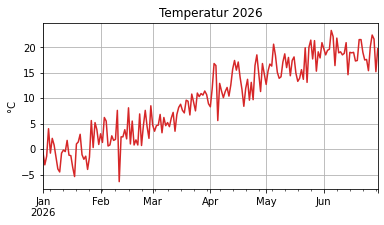

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
w['temperatur'].plot(color='C3', title='Temperatur 2026', ylabel='°C', xlabel='', grid=True, figsize=(6, 3))
plt.show()
```

</details>

#### Aufgabe 1.2

Zeichne die Temperatur und ihren gleitenden 7-Tage-Durchschnitt in ein Diagramm: Lege die Spalte `mittel7` an und zeichne `w[['temperatur', 'mittel7']]` mit den Farben `['lightgray', 'C0']`
(`color=` mit einer Liste), Titel `Temperatur und 7-Tage-Mittel`, Bildgröße 6 × 3.

**Erwartete Ausgabe:**



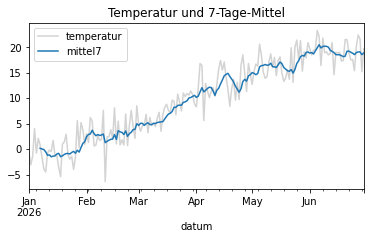

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
w['mittel7'] = w['temperatur'].rolling(7).mean()
w[['temperatur', 'mittel7']].plot(color=['lightgray', 'C0'], title='Temperatur und 7-Tage-Mittel', figsize=(6, 3))
plt.show()
```

</details>

#### Aufgabe 1.3

Zeichne die laufende Regensumme seit Jahresbeginn (`cumsum`) als Linie (Farbe `'C0'`), Titel `Regen seit 1. Januar`, y-Beschriftung `mm`, keine Legende, Bildgröße 5 × 3.

**Erwartete Ausgabe:**



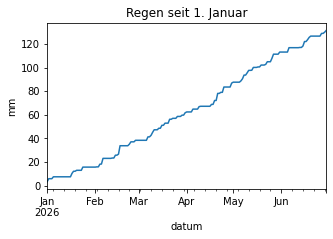

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
w['regen'].cumsum().plot(color='C0', title='Regen seit 1. Januar', ylabel='mm', legend=False, figsize=(5, 3))
plt.show()
```

</details>

#### Aufgabe 1.4

Zeichne für den Kiosk den Gesamtumsatz pro Tag (nach `datum` gruppieren) als Linie mit Punkten (`marker='o'`), Titel `Umsatz pro Tag`, y-Beschriftung `Euro`, Bildgröße 5 × 3.

**Erwartete Ausgabe:**



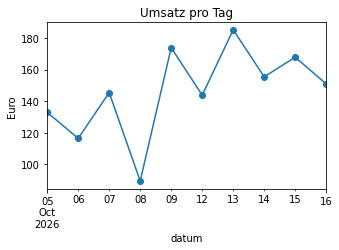

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k.groupby('datum')['umsatz'].sum().plot(marker='o', title='Umsatz pro Tag', ylabel='Euro', figsize=(5, 3))
plt.show()
```

</details>

## 2. Balkendiagramme

#### `plot.bar` und `plot.barh`

`df.plot.bar()` zeichnet **senkrechte** Balken, `df.plot.barh()` **waagrechte**. Bei einem DataFrame mit mehreren Spalten stehen die Balken nebeneinander,
mit `stacked=True` übereinander. `rot=0` dreht die Beschriftungen der x-Achse waagrecht.

Meist zeichnet man das Ergebnis einer Gruppierung oder eine Pivot-Tabelle.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k.groupby('kategorie')['umsatz'].sum().sort_values().plot.barh(color='C2', title='Umsatz pro Kategorie', xlabel='Euro', figsize=(5, 3))
plt.show()

#### Aufgabe 2.1

Zeichne die Einwohnerzahl (in Tausend) der Bundesländer als waagrechte Balken, sortiert nach Einwohnern (das größte oben: aufsteigend sortieren), mit dem Kürzel als Beschriftung
(`set_index('kuerzel')`), Farbe `'C0'`, Titel `Einwohner in Tausend`, ohne y-Beschriftung (`ylabel=''`), Bildgröße 5 × 5.

**Erwartete Ausgabe:**



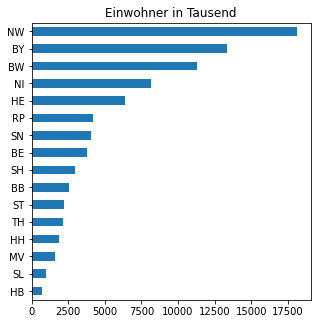

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l.set_index('kuerzel')['einwohner'].sort_values().plot.barh(color='C0', title='Einwohner in Tausend', ylabel='', figsize=(5, 5))
plt.show()
```

</details>

#### Aufgabe 2.2

Zeichne den Mathe-, Deutsch- und Englisch-Durchschnitt pro Klasse als gruppierte senkrechte Balken (`groupby` und `mean`), Titel `Notendurchschnitt`, waagrechte Beschriftungen (`rot=0`),
Bildgröße 5 × 3.

**Erwartete Ausgabe:**



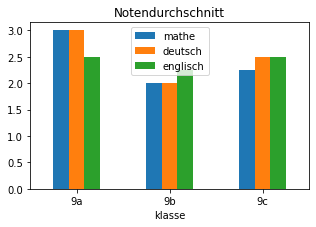

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
s.groupby('klasse')[['mathe', 'deutsch', 'englisch']].mean().plot.bar(rot=0, title='Notendurchschnitt', figsize=(5, 3))
plt.show()
```

</details>

#### Aufgabe 2.3

Zeichne die verkaufte Menge pro Wochentag (Montag bis Freitag in dieser Reihenfolge) und Kategorie als **gestapelte** Balken: Pivot-Tabelle mit den Tagen als Zeilen und den Kategorien als
Spalten, Zeilen mit `.loc[[...]]` ordnen. Titel `Verkauf pro Wochentag`, `rot=0`, Bildgröße 6 × 3.

**Erwartete Ausgabe:**



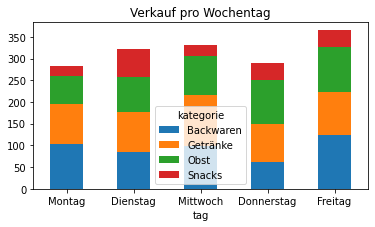

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
p = k.pivot_table(index='tag', columns='kategorie', values='menge', aggfunc='sum')
p = p.loc[['Montag', 'Dienstag', 'Mittwoch', 'Donnerstag', 'Freitag']]
p.plot.bar(stacked=True, rot=0, title='Verkauf pro Wochentag', figsize=(6, 3))
plt.show()
```

</details>

#### Aufgabe 2.4

Zeichne den Notenspiegel für Mathe (Anzahl der Schüler für die Noten 1 bis 6, auch 0 mit `reindex`) als senkrechte Balken in der Farbe `'C1'`, Titel `Mathe`, x-Beschriftung `Note`,
y-Beschriftung `Anzahl`, `rot=0`, Bildgröße 4 × 3.

**Erwartete Ausgabe:**



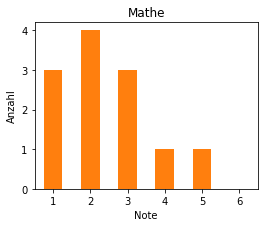

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
s['mathe'].value_counts().reindex(range(1, 7), fill_value=0).plot.bar(color='C1', title='Mathe', xlabel='Note', ylabel='Anzahl', rot=0, figsize=(4, 3))
plt.show()
```

</details>

## 3. Histogramme, Boxplots und Kreisdiagramme

#### Verteilungen

- `s.plot.hist(bins=10)` zeichnet ein **Histogramm**: wie viele Werte in welchem Bereich liegen. `edgecolor='black'` umrandet die Balken.
- `df.plot.box()` zeichnet für jede Spalte einen **Boxplot** (Median, Quartile, Minimum/Maximum, Ausreißer als Punkte).
- `s.plot.pie(autopct='%1.0f%%')` zeichnet ein **Kreisdiagramm** mit Prozentangaben.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
w['temperatur'].plot.hist(bins=15, edgecolor='black', ax=axs[0], title='Temperaturen')
w[['temperatur']].plot.box(ax=axs[1], title='Boxplot')
plt.show()

Mit `ax=` zeichnet `plot` in eine vorhandene Achse, z. B. in eines von mehreren Teildiagrammen aus `plt.subplots` (siehe Notebook matplotlib: Layout).

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axs = plt.subplots(1, 2, figsize=(4, 2))
pd.Series([1, 3, 2]).plot(ax=axs[0])
pd.Series([2, 1, 2]).plot.bar(ax=axs[1])
plt.show()

#### Aufgabe 3.1

Zeichne ein Histogramm der täglichen Regenmengen an Regentagen (`regen > 0`) mit 10 Klassen, schwarzen Rändern, Farbe `'C0'`, Titel `Regen an Regentagen`, x-Beschriftung `mm`, Bildgröße 4 × 3.

**Erwartete Ausgabe:**



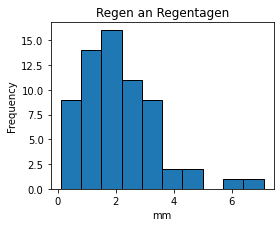

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
w.loc[w['regen'] > 0, 'regen'].plot.hist(bins=10, edgecolor='black', color='C0', title='Regen an Regentagen', figsize=(4, 3))
plt.xlabel('mm')
plt.show()
```

</details>

#### Aufgabe 3.2

Zeichne Boxplots der drei Notenspalten nebeneinander (`plot.box`), Titel `Noten`, Bildgröße 4 × 3.

**Erwartete Ausgabe:**



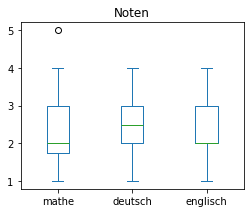

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
s[['mathe', 'deutsch', 'englisch']].plot.box(title='Noten', figsize=(4, 3))
plt.show()
```

</details>

`df.boxplot(column='wert', by='gruppe')` zeichnet für jede Gruppe einen eigenen Boxplot nebeneinander. `w.index.month` sind die Monate eines Datums-Index.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame({'g': ['a', 'a', 'b', 'b'], 'x': [1, 3, 2, 6]})
df.boxplot(column='x', by='g', figsize=(3, 2))
plt.suptitle('')
plt.show()

#### Aufgabe 3.3

Zeichne die Monatstemperaturen als Boxplots: eine Pivot-Tabelle ist hier unpraktisch. Lege eine Spalte `monat` an (`w.index.month`) und benutze `w.boxplot(column='temperatur', by='monat')` mit
`figsize=(6, 3)`. Setze danach den Titel `Temperatur pro Monat` mit `plt.title`, entferne den automatischen Obertitel mit `plt.suptitle('')`.

**Erwartete Ausgabe:**



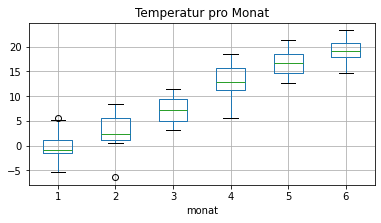

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
w['monat'] = w.index.month
w.boxplot(column='temperatur', by='monat', figsize=(6, 3))
plt.title('Temperatur pro Monat')
plt.suptitle('')
plt.show()
```

</details>

#### Aufgabe 3.4

Zeichne den Umsatzanteil der Kategorien des Kiosks als Kreisdiagramm mit Prozentangaben (`autopct='%1.0f%%'`), ohne y-Beschriftung (`ylabel=''`), Titel `Umsatzanteile`, Bildgröße 4 × 4.

**Erwartete Ausgabe:**



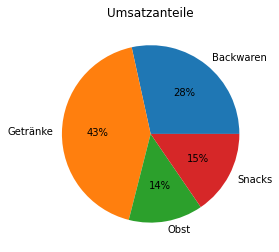

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k.groupby('kategorie')['umsatz'].sum().plot.pie(autopct='%1.0f%%', ylabel='', title='Umsatzanteile', figsize=(4, 4))
plt.show()
```

</details>

## 4. Streudiagramme und Korrelation

#### `plot.scatter` und `corr`

`df.plot.scatter(x='a', y='b')` zeichnet ein **Streudiagramm**: einen Punkt pro Zeile. So sieht man, ob zwei Größen zusammenhängen.

`df['a'].corr(df['b'])` ist der **Korrelationskoeffizient** r zwischen −1 und 1: Nahe 1 heißt „je größer a, desto größer b“, nahe −1 „je größer a, desto kleiner b“, nahe 0 „kein linearer Zusammenhang“.
`df[['a', 'b', 'c']].corr()` zeigt alle Paare als Tabelle.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
print(round(s['mathe'].corr(s['englisch']), 2))
s.plot.scatter(x='fehltage', y='mathe', title='Fehltage und Mathenote', figsize=(4, 3))
plt.show()

#### Aufgabe 4.1

Zeichne für die Bundesländer ein Streudiagramm mit der Fläche auf der x-Achse und den Einwohnern auf der y-Achse (Farbe `'C2'`, Titel `Fläche und Einwohner`, Bildgröße 4 × 3) und gib den
Korrelationskoeffizienten (2 Stellen) aus.

**Erwartete Ausgabe:**

```
0.72
```

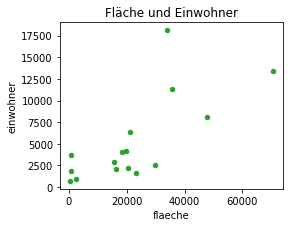

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
print(round(l['flaeche'].corr(l['einwohner']), 2))
l.plot.scatter(x='flaeche', y='einwohner', color='C2', title='Fläche und Einwohner', figsize=(4, 3))
plt.show()
```

</details>

#### Aufgabe 4.2

Lass die Korrelationstabelle der Spalten `mathe`, `deutsch`, `englisch` und `fehltage` (2 Stellen) anzeigen.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">mathe</th>
      <th style="text-align: right">deutsch</th>
      <th style="text-align: right">englisch</th>
      <th style="text-align: right">fehltage</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">mathe</th>
      <td style="text-align: right">1.00</td>
      <td style="text-align: right">0.70</td>
      <td style="text-align: right">0.73</td>
      <td style="text-align: right">0.95</td>
    </tr>
    <tr>
      <th style="text-align: right">deutsch</th>
      <td style="text-align: right">0.70</td>
      <td style="text-align: right">1.00</td>
      <td style="text-align: right">0.68</td>
      <td style="text-align: right">0.67</td>
    </tr>
    <tr>
      <th style="text-align: right">englisch</th>
      <td style="text-align: right">0.73</td>
      <td style="text-align: right">0.68</td>
      <td style="text-align: right">1.00</td>
      <td style="text-align: right">0.78</td>
    </tr>
    <tr>
      <th style="text-align: right">fehltage</th>
      <td style="text-align: right">0.95</td>
      <td style="text-align: right">0.67</td>
      <td style="text-align: right">0.78</td>
      <td style="text-align: right">1.00</td>
    </tr>
  </tbody>
</table>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('schueler.csv', sep=';')
s[['mathe', 'deutsch', 'englisch', 'fehltage']].corr().round(2)
```

</details>

#### Aufgabe 4.3

Zeichne das Streudiagramm Temperatur (x) gegen Regen (y) für alle Tage mit kleinen Punkten (`s=10`), Titel `Temperatur und Regen`, Bildgröße 4 × 3, und gib den Korrelationskoeffizienten (2 Stellen) aus.

**Erwartete Ausgabe:**

```
0.0
```

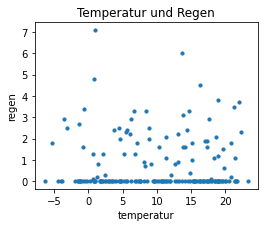

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
print(round(w['temperatur'].corr(w['regen']), 2))
w.plot.scatter(x='temperatur', y='regen', s=10, title='Temperatur und Regen', figsize=(4, 3))
plt.show()
```

</details>

#### Aufgabe 4.4

Beschrifte im Streudiagramm Fläche/Einwohner die Punkte der Stadtstaaten (Berlin, Hamburg, Bremen) mit ihrem Kürzel (`ax.annotate(text, (x, y))` in einer Schleife über die drei Zeilen,
`itertuples()`). Titel `Stadtstaaten`, Bildgröße 4 × 3.

**Erwartete Ausgabe:**



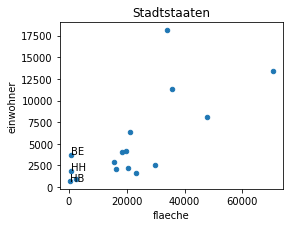

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
ax = l.plot.scatter(x='flaeche', y='einwohner', title='Stadtstaaten', figsize=(4, 3))
for z in l[l['kuerzel'].isin(['BE', 'HH', 'HB'])].itertuples():
    ax.annotate(z.kuerzel, (z.flaeche, z.einwohner))
plt.show()
```

</details>

## 5. Projekt: Bundesländer

#### Von der Frage zum Diagramm

Eine kleine Datenanalyse hat meist diese Schritte: **Frage** stellen, Daten **einlesen**, **aufbereiten** (neue Spalten, filtern), **auswerten** (sortieren, gruppieren) und das Ergebnis als
**Tabelle oder Diagramm** darstellen. Die folgenden Aufgaben bauen aufeinander auf; die Zwischenschritte stehen jeweils schon in der Codezelle.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
l.sort_values('dichte', ascending=False).head(3)

#### Aufgabe 5.1

Welche Bundesländer sind dichter besiedelt als Deutschland insgesamt? Berechne die Dichte für Deutschland (Summe der Einwohner · 1000 / Summe der Flächen, ganze Zahl) und gib sie aus.
Lass dann Land und Dichte der dichter besiedelten Länder sortiert anzeigen.

**Erwartete Ausgabe:**

```
236
```

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">land</th>
      <th style="text-align: right">dichte</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">Berlin</td>
      <td style="text-align: right">4220.0</td>
    </tr>
    <tr>
      <th style="text-align: right">5</th>
      <td style="text-align: right">Hamburg</td>
      <td style="text-align: right">2503.0</td>
    </tr>
    <tr>
      <th style="text-align: right">4</th>
      <td style="text-align: right">Bremen</td>
      <td style="text-align: right">1623.0</td>
    </tr>
    <tr>
      <th style="text-align: right">9</th>
      <td style="text-align: right">Nordrhein-Westfalen</td>
      <td style="text-align: right">532.0</td>
    </tr>
    <tr>
      <th style="text-align: right">11</th>
      <td style="text-align: right">Saarland</td>
      <td style="text-align: right">385.0</td>
    </tr>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">Baden-Württemberg</td>
      <td style="text-align: right">316.0</td>
    </tr>
    <tr>
      <th style="text-align: right">6</th>
      <td style="text-align: right">Hessen</td>
      <td style="text-align: right">303.0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
d = round(l['einwohner'].sum() * 1000 / l['flaeche'].sum())
print(d)
l.loc[l['dichte'] > d, ['land', 'dichte']].sort_values('dichte', ascending=False)
```

</details>

#### Aufgabe 5.2

Teile die Länder in **Stadtstaaten** (BE, HH, HB) und **Flächenländer** ein (Spalte `art`) und lass pro Art die Summe von Einwohnern und Fläche und die Dichte (ganze Zahl) anzeigen.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">einwohner</th>
      <th style="text-align: right">flaeche</th>
      <th style="text-align: right">dichte</th>
    </tr>
    <tr>
      <th style="text-align: right">art</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">Flächenland</th>
      <td style="text-align: right">78020</td>
      <td style="text-align: right">355521</td>
      <td style="text-align: right">219</td>
    </tr>
    <tr>
      <th style="text-align: right">Stadtstaat</th>
      <td style="text-align: right">6330</td>
      <td style="text-align: right">2065</td>
      <td style="text-align: right">3065</td>
    </tr>
  </tbody>
</table>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
l['art'] = l['kuerzel'].apply(lambda x: 'Stadtstaat' if x in ['BE', 'HH', 'HB'] else 'Flächenland')
g = l.groupby('art')[['einwohner', 'flaeche']].sum()
g['dichte'] = (g['einwohner'] * 1000 / g['flaeche']).round(0).astype(int)
g
```

</details>

#### Aufgabe 5.3

Zeichne die Dichte der **Flächenländer** als senkrechte Balken (Kürzel als Beschriftung, nach Dichte absteigend), Farbe `'C4'`, mit einer waagrechten gestrichelten Linie für die Dichte
Deutschlands (`plt.axhline(d, color='black', linestyle='--')`), Titel `Einwohner pro km²`, `rot=0`, ohne x-Beschriftung, Bildgröße 6 × 3.

**Erwartete Ausgabe:**



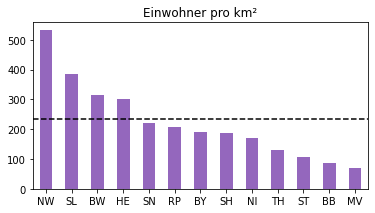

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

l = pd.read_csv('laender.csv')
l['dichte'] = (l['einwohner'] * 1000 / l['flaeche']).round(0)
d = round(l['einwohner'].sum() * 1000 / l['flaeche'].sum())
fl = l[~l['kuerzel'].isin(['BE', 'HH', 'HB'])].set_index('kuerzel')['dichte'].sort_values(ascending=False)
fl.plot.bar(color='C4', title='Einwohner pro km²', rot=0, xlabel='', figsize=(6, 3))
plt.axhline(d, color='black', linestyle='--')
plt.show()
```

</details>

## 6. Projekt: Schulkiosk

#### Aufgabe 6.1

Der Kiosk will wissen, welche Artikel sich lohnen. Lass pro Artikel Menge und Umsatz (2 Stellen) und den Anteil am Gesamtumsatz in Prozent (1 Stelle, Spalte `anteil`) anzeigen,
nach Umsatz absteigend.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">menge</th>
      <th style="text-align: right">umsatz</th>
      <th style="text-align: right">anteil</th>
    </tr>
    <tr>
      <th style="text-align: right">artikel</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">Apfelschorle</th>
      <td style="text-align: right">267</td>
      <td style="text-align: right">400.5</td>
      <td style="text-align: right">27.4</td>
    </tr>
    <tr>
      <th style="text-align: right">Brezel</th>
      <td style="text-align: right">288</td>
      <td style="text-align: right">230.4</td>
      <td style="text-align: right">15.8</td>
    </tr>
    <tr>
      <th style="text-align: right">Müsliriegel</th>
      <td style="text-align: right">188</td>
      <td style="text-align: right">225.6</td>
      <td style="text-align: right">15.4</td>
    </tr>
    <tr>
      <th style="text-align: right">Wasser</th>
      <td style="text-align: right">222</td>
      <td style="text-align: right">222.0</td>
      <td style="text-align: right">15.2</td>
    </tr>
    <tr>
      <th style="text-align: right">Laugenstange</th>
      <td style="text-align: right">185</td>
      <td style="text-align: right">185.0</td>
      <td style="text-align: right">12.7</td>
    </tr>
    <tr>
      <th style="text-align: right">Apfel</th>
      <td style="text-align: right">212</td>
      <td style="text-align: right">106.0</td>
      <td style="text-align: right">7.3</td>
    </tr>
    <tr>
      <th style="text-align: right">Banane</th>
      <td style="text-align: right">229</td>
      <td style="text-align: right">91.6</td>
      <td style="text-align: right">6.3</td>
    </tr>
  </tbody>
</table>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
g = k.groupby('artikel')[['menge', 'umsatz']].sum().round(2)
g['anteil'] = (g['umsatz'] / g['umsatz'].sum() * 100).round(1)
g.sort_values('umsatz', ascending=False)
```

</details>

#### Aufgabe 6.2

Vergleiche die beiden Wochen: Lass eine Pivot-Tabelle mit den Artikeln als Zeilen, den Wochen als Spalten und der Menge anzeigen, mit einer Spalte `plus` (Woche 2 minus Woche 1),
nach `plus` absteigend sortiert (bei Gleichstand nach Artikel: erst `reset_index()`, dann nach `['plus', 'artikel']` sortieren und `artikel` wieder zum Index machen).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right">woche</th>
      <th style="text-align: right">1</th>
      <th style="text-align: right">2</th>
      <th style="text-align: right">plus</th>
    </tr>
    <tr>
      <th style="text-align: right">artikel</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">Wasser</th>
      <td style="text-align: right">78</td>
      <td style="text-align: right">144</td>
      <td style="text-align: right">66</td>
    </tr>
    <tr>
      <th style="text-align: right">Müsliriegel</th>
      <td style="text-align: right">70</td>
      <td style="text-align: right">118</td>
      <td style="text-align: right">48</td>
    </tr>
    <tr>
      <th style="text-align: right">Laugenstange</th>
      <td style="text-align: right">73</td>
      <td style="text-align: right">112</td>
      <td style="text-align: right">39</td>
    </tr>
    <tr>
      <th style="text-align: right">Banane</th>
      <td style="text-align: right">97</td>
      <td style="text-align: right">132</td>
      <td style="text-align: right">35</td>
    </tr>
    <tr>
      <th style="text-align: right">Brezel</th>
      <td style="text-align: right">146</td>
      <td style="text-align: right">142</td>
      <td style="text-align: right">-4</td>
    </tr>
    <tr>
      <th style="text-align: right">Apfelschorle</th>
      <td style="text-align: right">139</td>
      <td style="text-align: right">128</td>
      <td style="text-align: right">-11</td>
    </tr>
    <tr>
      <th style="text-align: right">Apfel</th>
      <td style="text-align: right">118</td>
      <td style="text-align: right">94</td>
      <td style="text-align: right">-24</td>
    </tr>
  </tbody>
</table>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
p = k.pivot_table(index='artikel', columns='woche', values='menge', aggfunc='sum')
p['plus'] = p[2] - p[1]
p.reset_index().sort_values(['plus', 'artikel'], ascending=[False, True]).set_index('artikel')
```

</details>

#### Aufgabe 6.3

Zeichne die Menge pro Artikel für beide Wochen als gruppierte waagrechte Balken (Pivot-Tabelle mit den Wochen als Spalten), Titel `Woche 1 und 2`, Bildgröße 5 × 4.

**Erwartete Ausgabe:**



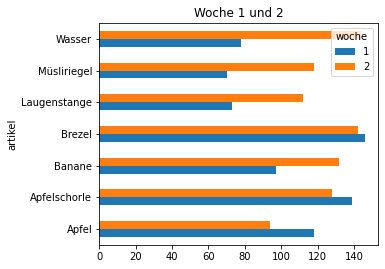

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
p = k.pivot_table(index='artikel', columns='woche', values='menge', aggfunc='sum')
p.plot.barh(title='Woche 1 und 2', figsize=(5, 4))
plt.show()
```

</details>

#### Aufgabe 6.4

Freitags gibt es mehr Backwaren. Zeichne für die Kategorie `Backwaren` die Menge pro Datum als Linie mit Punkten, Titel `Backwaren`, y-Beschriftung `Stück`, Bildgröße 5 × 3,
und gib die durchschnittliche Menge an Freitagen und an den anderen Tagen (1 Stelle) aus.

**Erwartete Ausgabe:**

```
62.5 43.5
```

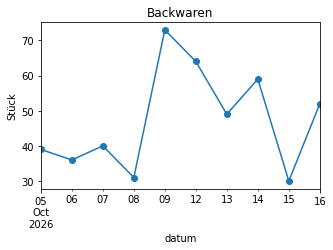

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

k = pd.read_csv('kiosk.csv', sep=';', parse_dates=['datum'])
k['umsatz'] = k['menge'] * k['preis']
k['woche'] = k['datum'].apply(lambda d: 1 if d < pd.Timestamp('2026-10-12') else 2)
b = k[k['kategorie'] == 'Backwaren']
pro_tag = b.groupby('datum')['menge'].sum()
fr = b.groupby(['datum', 'tag'])['menge'].sum().reset_index()
print(round(fr.loc[fr['tag'] == 'Freitag', 'menge'].mean(), 1), round(fr.loc[fr['tag'] != 'Freitag', 'menge'].mean(), 1))
pro_tag.plot(marker='o', title='Backwaren', ylabel='Stück', figsize=(5, 3))
plt.show()
```

</details>

## 7. Projekt: Wetter

#### Aufgabe 7.1

Erstelle eine Monatsübersicht: pro Monat die mittlere, die höchste und die tiefste Temperatur (1 Stelle), die Regensumme (1 Stelle) und die Zahl der Regentage (Spalten `mittel`, `max`, `min`,
`regen`, `regentage`). Benutze `resample('ME').agg(...)` mit benannten Kennzahlen und setze danach den Index auf die Monatsnamen in `monate`.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">mittel</th>
      <th style="text-align: right">max</th>
      <th style="text-align: right">min</th>
      <th style="text-align: right">regen</th>
      <th style="text-align: right">regentage</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">Jan</th>
      <td style="text-align: right">-0.3</td>
      <td style="text-align: right">5.6</td>
      <td style="text-align: right">-5.4</td>
      <td style="text-align: right">15.7</td>
      <td style="text-align: right">7</td>
    </tr>
    <tr>
      <th style="text-align: right">Feb</th>
      <td style="text-align: right">3.2</td>
      <td style="text-align: right">8.5</td>
      <td style="text-align: right">-6.4</td>
      <td style="text-align: right">22.7</td>
      <td style="text-align: right">11</td>
    </tr>
    <tr>
      <th style="text-align: right">Mär</th>
      <td style="text-align: right">7.4</td>
      <td style="text-align: right">11.4</td>
      <td style="text-align: right">3.2</td>
      <td style="text-align: right">23.3</td>
      <td style="text-align: right">12</td>
    </tr>
    <tr>
      <th style="text-align: right">Apr</th>
      <td style="text-align: right">13.0</td>
      <td style="text-align: right">18.5</td>
      <td style="text-align: right">5.6</td>
      <td style="text-align: right">25.1</td>
      <td style="text-align: right">10</td>
    </tr>
    <tr>
      <th style="text-align: right">Mai</th>
      <td style="text-align: right">16.8</td>
      <td style="text-align: right">21.4</td>
      <td style="text-align: right">12.7</td>
      <td style="text-align: right">26.3</td>
      <td style="text-align: right">15</td>
    </tr>
    <tr>
      <th style="text-align: right">Jun</th>
      <td style="text-align: right">19.2</td>
      <td style="text-align: right">23.3</td>
      <td style="text-align: right">14.6</td>
      <td style="text-align: right">18.3</td>
      <td style="text-align: right">10</td>
    </tr>
  </tbody>
</table>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
monate = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
monate = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun']
w['regentag'] = w['regen'] > 0
m = w.resample('ME').agg(mittel=('temperatur', 'mean'), max=('temperatur', 'max'), min=('temperatur', 'min'),
                         regen=('regen', 'sum'), regentage=('regentag', 'sum')).round(1)
m.index = monate
m
```

</details>

#### Aufgabe 7.2

Zeichne ein **Klimadiagramm**: Regensumme pro Monat als blaue Balken (`'C0'`) und das Monatsmittel der Temperatur als rote Linie mit Punkten (`'C3'`, `marker='o'`) auf einer
zweiten y-Achse (`ax2 = ax.twinx()`). Beschrifte die Achsen mit `mm` und `°C`, setze die Monatsnamen als x-Beschriftungen (`ax.set_xticks(range(6))`, `ax.set_xticklabels(monate)`),
Titel `Klimadiagramm Januar bis Juni`, Bildgröße 5 × 3.

**Erwartete Ausgabe:**



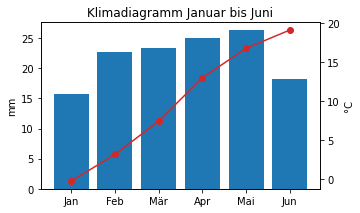

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
monate = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
monate = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun']
m = w.resample('ME').agg({'temperatur': 'mean', 'regen': 'sum'})
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(range(6), m['regen'], color='C0')
ax.set_ylabel('mm')
ax2 = ax.twinx()
ax2.plot(range(6), m['temperatur'], color='C3', marker='o')
ax2.set_ylabel('°C')
ax.set_xticks(range(6))
ax.set_xticklabels(monate)
ax.set_title('Klimadiagramm Januar bis Juni')
plt.show()
```

</details>

#### Aufgabe 7.3

Wie oft folgt auf einen Regentag wieder ein Regentag? Berechne mit `shift(1)` für jeden Tag, ob der Vortag ein Regentag war, und gib den Anteil der Regentage nach einem Regentag und nach einem
trockenen Tag (jeweils Prozent, 1 Stelle) aus.

**Erwartete Ausgabe:**

```
32.8
37.6
```

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import pandas as pd

w = pd.read_csv('wetter.csv', parse_dates=['datum']).set_index('datum')
nass = w['regen'] > 0
vortag = nass.shift(1, fill_value=False)
print(round(nass[vortag].mean() * 100, 1))
print(round(nass[~vortag].mean() * 100, 1))
```

</details>